<a href="https://colab.research.google.com/github/neylami/IndoBert-for-Fake-News-Detection/blob/main/projek_ml_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Deteksi Hoaks pada Teks Berita Menggunakan Model Transformer IndoBERT

Anggota Kelompok:

Khalisha Zahra Solichin (1306623016)   
Neyla Mearanti Ilham (1306623042)  
Yulia Arifah Rachman (1306623043)  

1. **Problem Statement**

Penyebaran hoaks pada teks berita di Indonesia semakin meningkat seiring pesatnya perkembangan teknologi informasi, sementara informasi hoaks sering sulit dibedakan dari berita faktual karena memiliki pola bahasa yang serupa dan berpotensi menimbulkan dampak sosial yang negative.  Metode deteksi manual maupun berbasis aturan sederhana belum mampu menangani volume data yang besar dan variasi bahasa yang kompleks secara efisien. Model berbasis Transformer seperti IndoBERT memiliki kemampuan memahami konteks semantik bahasa Indonesia, namun masih terbatas evaluasinya untuk mendeteksi hoaks secara akurat pada teks berita berbahasa Indonesia. **Oleh karena itu, projek ini berfokus pada penerapan IndoBERT sebagai solusi untuk mendeteksi hoaks secara akurat pada teks berita berbahasa Indonesia.**


2. **Algoritma**

1.	Mulai  
2.	Persiapan Data  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;2.1. Mengumpulkan dataset berita.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;2.2. Memberikan label kelas pada setiap data berita.  
3.	Preprocessing Teks  
Untuk setiap teks berita dilakukan langkah berikut:  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3.1. Mengubah seluruh karakter menjadi huruf kecil.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3.2. Menghapus URL.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3.3. Menghapus angka dan tanda baca.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3.4. Menghapus spasi berlebih.  
Langkah preprocessing ini bertujuan untuk mengurangi noise tanpa menghilangkan konteks semantik teks.  
4.	Pembagian Dataset  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4.1. Dataset dibagi menjadi:  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4.1.1. Data latih (training set).  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4.1.2. Data uji (testing set).  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4.2. Pelatihan Model Baseline  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4.2.1. Melakukan ekstraksi fitur teks menggunakan metode TF-IDF.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4.2.2. Melatih model Logistic Regression menggunakan fitur TF-IDF.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4.2.3. Menghasilkan prediksi dan menghitung metrik evaluasi.  
5.	Tokenisasi  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;5.1. Teks hasil preprocessing diproses menggunakan tokenizer IndoBERT.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;5.2. Menambahkan token khusus [CLS] di awal teks dan [SEP] di akhir teks.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;5.3. Melakukan padding atau truncation hingga panjang maksimum yang telah ditentukan.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;5.4. Menghasilkan input_ids dan attention_mask.  
6.	Inisialisasi Model  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;6.1. Menggunakan model pre-trained IndoBERT.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;6.2. Menambahkan lapisan klasifikasi (classification head) pada output token [CLS].  
7.	Proses Pelatihan Model  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Proses traning data dilakukan menggunakan data train dengan langkah berikut:  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;7.1. Memasukkan input_ids dan attention_mask ke dalam model.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;7.2. Menghitung keluaran model berupa probabilitas kelas.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;7.3. Menghitung nilai loss menggunakan fungsi Cross-Entropy Loss.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;7.4. Melakukan backpropagation untuk memperbarui bobot model.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;7.5. Proses ini diulang selama beberapa epoch hingga model konvergen.  
8.	Evaluasi Model  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;8.1. Model diuji menggunakan data uji.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;8.2. Menghasilkan prediksi kelas untuk setiap data uji.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;8.3. Menghitung metrik evaluasi seperti accuracy, precision, recall, dan F1-score.  
9.	Prediksi Data Baru  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;9.1. Teks berita baru diproses melalui tahap preprocessing dan tokenisasi.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;9.2. Data dimasukkan ke dalam model yang telah dilatih.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;9.3. Model menghasilkan label prediksi berupa hoaks atau non-hoaks.  
10. Selesai  



3. **Flowchart**

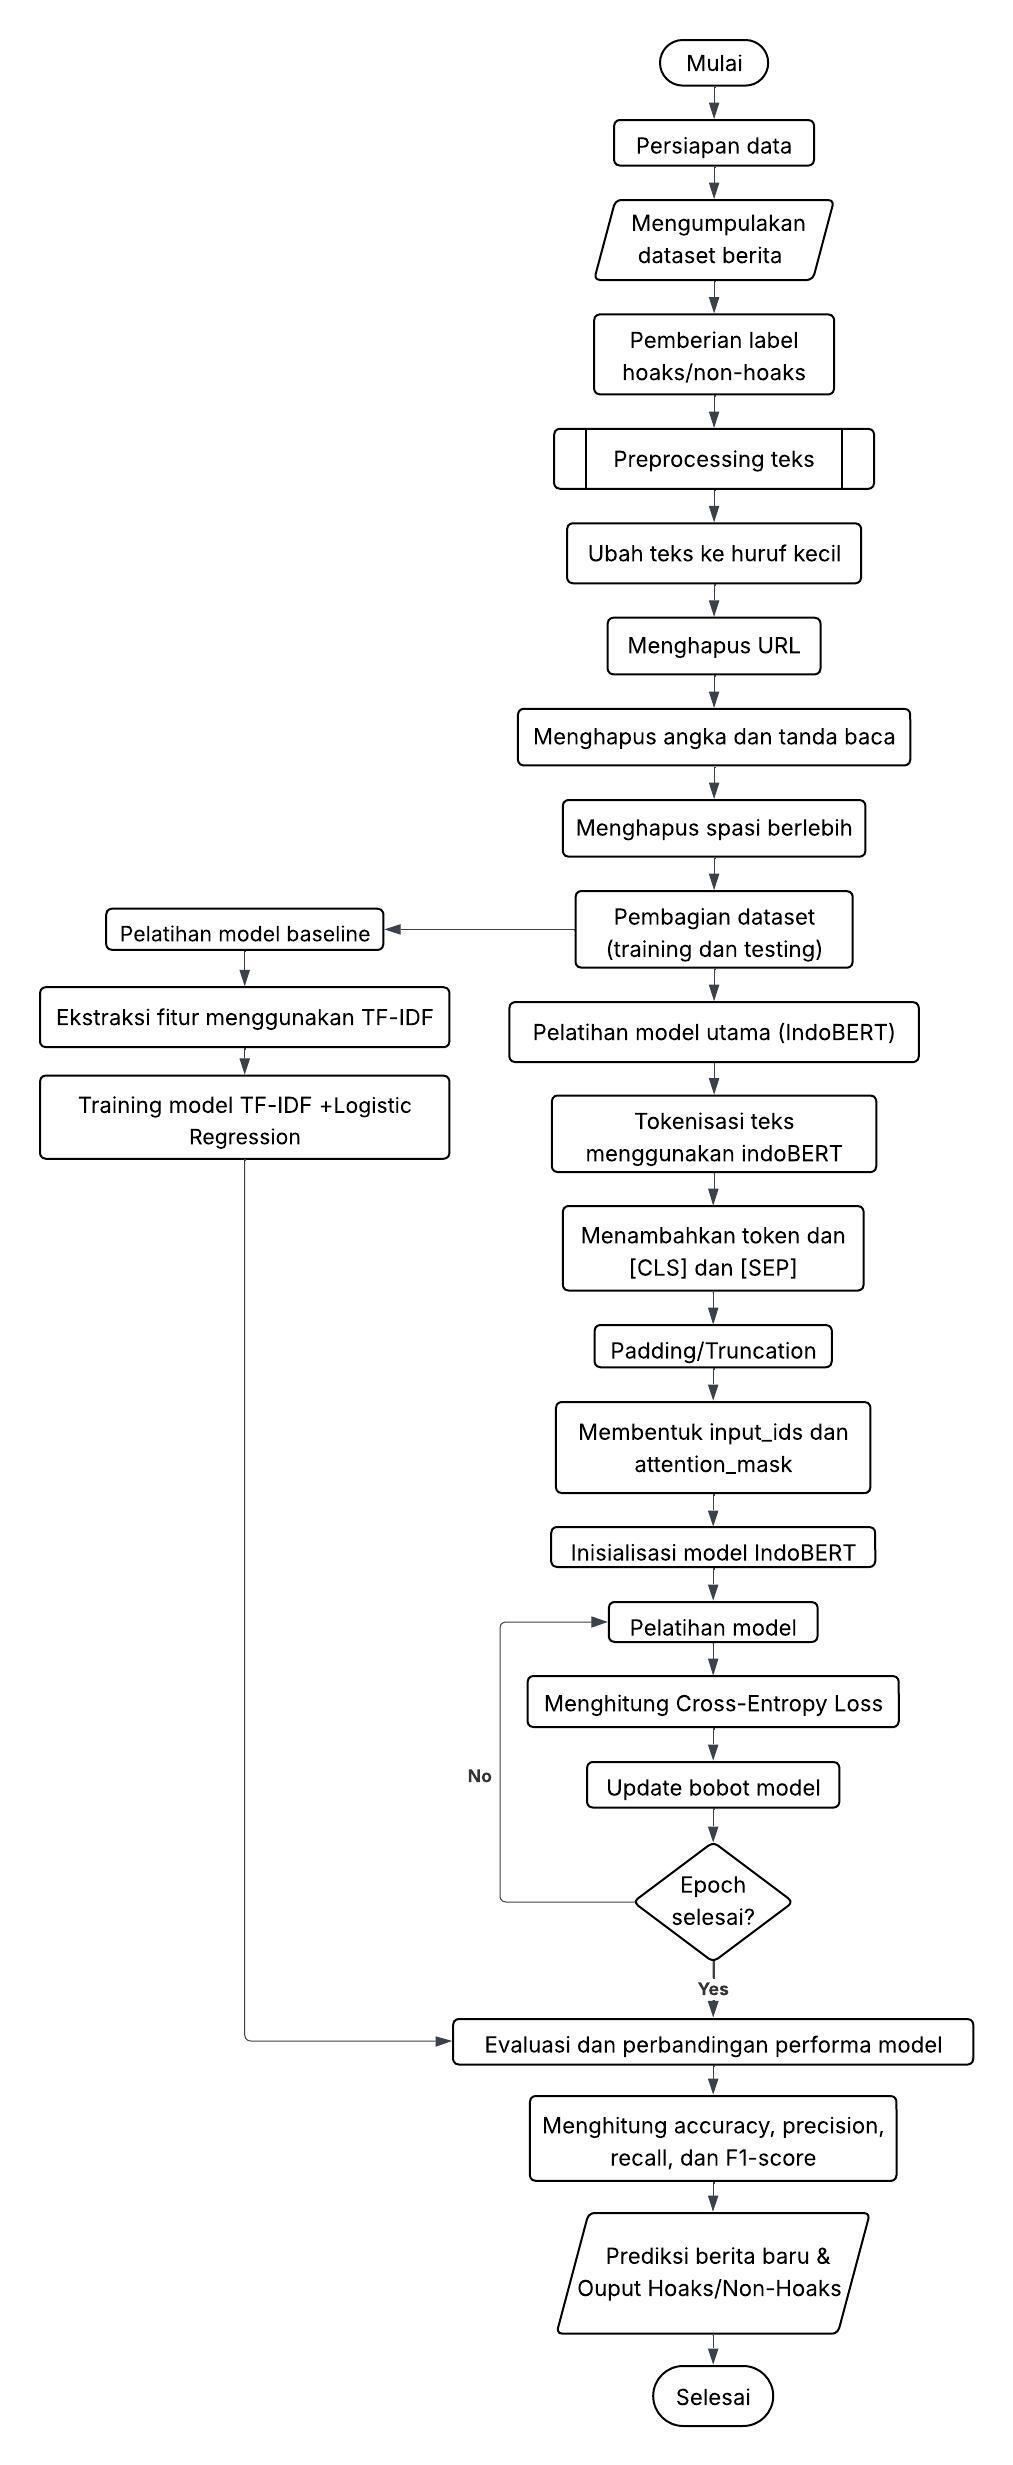

4. **Source Code**

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
import pandas as pd
path = "/content/gdrive/MyDrive/Projek ML/"

cnn = pd.read_excel(path + "dataset_cnn_summarized.xlsx")
kompas = pd.read_excel(path + "dataset_kompas_summarized.xlsx")
tempo = pd.read_excel(path + "dataset_tempo_summarized.xlsx")
turnback = pd.read_excel(path + "dataset_turnbackhoax_summarized.xlsx")

print("Data loaded successfully!")

Data loaded successfully!


In [ ]:
print("Ukuran data CNN:", cnn.shape)
print("Ukuran data Kompas:", kompas.shape)
print("Ukuran data Tempo:", tempo.shape)
print("Ukuran data Turnback Hoax:", turnback.shape)

Ukuran data CNN: (9630, 12)
Ukuran data Kompas: (4729, 12)
Ukuran data Tempo: (6592, 12)
Ukuran data Turnback Hoax: (10381, 14)


In [ ]:
df = pd.concat([cnn, kompas, tempo, turnback], ignore_index=True)
print("Ukuran data gabungan:", df.shape)
df.head()

Ukuran data gabungan: (31332, 14)


,index,title,raw timestamp,original,tags,author,url,cleaned,label,timestamp,cleaned token length,summarized,politik,raw narasi
0,0,Anies di Milad BKMT: Pengajian Menghasilkan Ib...,"Selasa, 21 Feb 2023 21:22 WIB","Jakarta, CNN Indonesia -- Mantan Gubernur DKI ...",anies baswedan;pengajian;pilpres 2024;badan ko...,CNN Indonesia,https://www.cnnindonesia.com/nasional/20230221...,Anies di Milad BKMT: Pengajian Menghasilkan Ib...,0,2023-02-21 21:22:00,401,Mantan Gubernur DKI Jakarta Anies Baswedan men...,NaN,NaN
1,1,Edy Soal Pilgub Sumut: Kalau yang Maju Abal-ab...,"Selasa, 21 Feb 2023 20:46 WIB","Medan, CNN Indonesia -- Gubernur Sumatera Utar...",edy rahmayadi;pemilu 2024;pilkada 2024,CNN Indonesia,https://www.cnnindonesia.com/nasional/20230221...,Edy Soal Pilgub Sumut: Kalau yang Maju Abal-ab...,0,2023-02-21 20:46:00,410,Gubernur Sumatera Utara Edy Rahmayadi membuka ...,NaN,NaN
2,2,PKB Bakal Daftarkan Menaker Ida Fauziyah Jadi ...,"Selasa, 21 Feb 2023 20:33 WIB","Jakarta, CNN Indonesia -- Partai Kebangkitan B...",ida fauziyah;pkb;pemilu 2024;pileg 2024,CNN Indonesia,https://www.cnnindonesia.com/nasional/20230221...,PKB Bakal Daftarkan Menaker Ida Fauziyah Jadi ...,0,2023-02-21 20:33:00,285,PKB bakal mengusung Menteri Ketenagakerjaan Id...,NaN,NaN
3,3,Gede Pasek Doakan AHY Jadi Capres atau Cawapres,"Selasa, 21 Feb 2023 19:58 WIB","Jakarta, CNN Indonesia -- Ketua Umum Partai Ke...",gede pasek suardika;ahy;pilpres 2024;pemilu 20...,CNN Indonesia,https://www.cnnindonesia.com/nasional/20230221...,Gede Pasek Doakan AHY Jadi Capres atau Cawapre...,0,2023-02-21 19:58:00,279,Ketua Umum Partai Kebangkitan Nusantara (PKN) ...,NaN,NaN
4,4,PKN Siapkan Jabatan Khusus Buat Anas Urbaningr...,"Selasa, 21 Feb 2023 18:56 WIB","Jakarta, CNN Indonesia -- Dewan Pimpinan Pusat...",anas urbaningrum;pkn;pemilu 2024,CNN Indonesia,https://www.cnnindonesia.com/nasional/20230221...,PKN Siapkan Jabatan Khusus Buat Anas Urbaningr...,0,2023-02-21 18:56:00,305,Dewan Pimpinan Pusat PKN menyiapkan jabatan kh...,NaN,NaN


In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
nltk.download('stopwords')

stop_words = set(stopwords.words('indonesian'))
ps = PorterStemmer()

TEXT_COLUMN = "original"

def clean_text(text):
    if pd.isna(text):
        return ""

    text = text.lower()

    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text).strip()

    words = text.split()

    words = [w for w in words if w not in stop_words]

    return " ".join(words)

df["clean_text"] = df[TEXT_COLUMN].apply(clean_text)

df[["original", "clean_text"]].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,original,clean_text
0,"Jakarta, CNN Indonesia -- Mantan Gubernur DKI ...",jakarta cnn indonesia mantan gubernur dki jaka...
1,"Medan, CNN Indonesia -- Gubernur Sumatera Utar...",medan cnn indonesia gubernur sumatera utara ed...
2,"Jakarta, CNN Indonesia -- Partai Kebangkitan B...",jakarta cnn indonesia partai kebangkitan bangs...
3,"Jakarta, CNN Indonesia -- Ketua Umum Partai Ke...",jakarta cnn indonesia ketua partai kebangkitan...
4,"Jakarta, CNN Indonesia -- Dewan Pimpinan Pusat...",jakarta cnn indonesia dewan pimpinan pusat dpp...


In [ ]:
# gunakan kolom teks yang benar
TEXT_COL = "original"

# Cek data kosong
print("Data kosong sebelum dibersihkan:")
print(df.isnull().sum())

# Buang baris yang tidak punya teks atau label
df = df.dropna(subset=[TEXT_COL, "label"])

# Cek jumlah duplikat
print("Jumlah duplikat:", df.duplicated().sum())

# Hapus duplikat
df = df.drop_duplicates()


Data kosong sebelum dibersihkan:
index                       0
title                       0
raw timestamp               0
original                    6
tags                      141
author                    316
url                         0
cleaned                  3885
label                       0
timestamp                   0
cleaned token length        0
summarized               4397
politik                 20951
raw narasi              20951
clean_text                  0
dtype: int64
Jumlah duplikat: 0


In [ ]:
print("\nJumlah duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Jumlah data setelah menghapus duplikat:", len(df))



Jumlah duplikat: 0
Jumlah data setelah menghapus duplikat: 31326


In [ ]:
from sklearn.model_selection import train_test_split

train, temp = train_test_split(df, test_size=0.3, random_state=42, stratify=df["label"])
val, test = train_test_split(temp, test_size=0.5, random_state=42, stratify=temp["label"])

print("\nUkuran dataset akhir:")
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))


Ukuran dataset akhir:
Train: 21928
Validation: 4699
Test: 4699


In [ ]:
output_path = "/content/gdrive/MyDrive/Projek ML/final_dataset/"

!mkdir -p "$output_path"

train.to_csv(output_path + "train.csv", index=False)
val.to_csv(output_path + "val.csv", index=False)
test.to_csv(output_path + "test.csv", index=False)

print("\nDataset final berhasil disimpan di folder:")
print(output_path)


Dataset final berhasil disimpan di folder:
/content/gdrive/MyDrive/Projek ML/final_dataset/


In [ ]:
!pip install transformers datasets --quiet

In [ ]:
import os
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer
from datasets import Dataset
import pandas as pd
import torch

In [ ]:
train_df = pd.read_csv('/content/gdrive/MyDrive/Projek ML/final_dataset/train.csv')
val_df = pd.read_csv('/content/gdrive/MyDrive/Projek ML/final_dataset/val.csv')
test_df = pd.read_csv("/content/gdrive/MyDrive/Projek ML/final_dataset/test.csv")

In [ ]:
train_df.info()
val_df.info()
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21928 entries, 0 to 21927
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 21928 non-null  int64  
 1   title                 21928 non-null  object 
 2   raw timestamp         21928 non-null  object 
 3   original              21928 non-null  object 
 4   tags                  21828 non-null  object 
 5   author                21699 non-null  object 
 6   url                   21928 non-null  object 
 7   cleaned               19254 non-null  object 
 8   label                 21928 non-null  int64  
 9   timestamp             21928 non-null  object 
 10  cleaned token length  21928 non-null  int64  
 11  summarized            18916 non-null  object 
 12  politik               7267 non-null   float64
 13  raw narasi            7267 non-null   object 
 14  clean_text            21928 non-null  object 
dtypes: float64(1), int6

In [ ]:
train_df = train_df.dropna(subset=["clean_text", "label"])
val_df   = val_df.dropna(subset=["clean_text", "label"])
test_df  = test_df.dropna(subset=["clean_text", "label"])

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

In [ ]:
train_ds = Dataset.from_pandas(train_df)
val_ds   = Dataset.from_pandas(val_df)
test_ds  = Dataset.from_pandas(test_df)

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("indobenchmark/indobert-base-p1")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [ ]:
def tokenize(batch):
    return tokenizer(
        batch["clean_text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

In [ ]:
train_tok = train_ds.map(tokenize, batched=True)
val_tok   = val_ds.map(tokenize, batched=True)
test_tok  = test_ds.map(tokenize, batched=True)

train_tok = train_tok.remove_columns(["clean_text"])
val_tok   = val_tok.remove_columns(["clean_text"])
test_tok  = test_tok.remove_columns(["clean_text"])

train_tok.set_format("torch")
val_tok.set_format("torch")
test_tok.set_format("torch")

Map:   0%|          | 0/21928 [00:00<?, ? examples/s]

Map:   0%|          | 0/4699 [00:00<?, ? examples/s]

Map:   0%|          | 0/4699 [00:00<?, ? examples/s]

In [ ]:
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    report_to="none"
)

In [ ]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {
        'accuracy': accuracy_score(labels, predictions),
        'f1': f1_score(labels, predictions, average='weighted'),
        'precision': precision_score(labels, predictions, average='weighted'),
        'recall': recall_score(labels, predictions, average='weighted')
    }

In [ ]:
def model_init():
    return AutoModelForSequenceClassification.from_pretrained(
        "indobenchmark/indobert-base-p1",
        num_labels=2
    )

In [ ]:
trainer_template = Trainer(
    model_init=model_init,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

/tmp/ipython-input-1290894056.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_template = Trainer(


pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
!pip install optuna --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.7/404.7 kB 20.6 MB/s eta 0:00:00


In [ ]:
best_run = trainer_template.hyperparameter_search(
    n_trials=5,
    direction="minimize"
)

[I 2025-12-13 14:26:16,837] A new study created in memory with name: no-name-d61f5932-4da1-4931-adf2-6580a2b3f857
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.014600,0.004480,0.998510,0.998510,0.998511,0.998510
2,0.006000,0.003501,0.998723,0.998723,0.998723,0.998723
3,0.005700,0.003212,0.998723,0.998723,0.998723,0.998723


[I 2025-12-13 14:52:40,009] Trial 0 finished with value: 3.994892317229942 and parameters: {'learning_rate': 1.5769813224825747e-06, 'num_train_epochs': 3, 'seed': 36, 'per_device_train_batch_size': 32}. Best is trial 0 with value: 3.994892317229942.
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.643000,0.637578,0.668653,0.535877,0.447097,0.668653
2,0.035600,0.032016,0.995531,0.995531,0.995530,0.995531
3,0.034400,0.029004,0.995744,0.995744,0.995744,0.995744
4,0.014900,0.029178,0.995744,0.995744,0.995744,0.995744
5,0.062700,0.029282,0.995744,0.995744,0.995744,0.995744


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
[I 2025-12-13 15:45:45,243] Trial 1 finished with value: 3.982975101085337 and parameters: {'learning_rate': 8.434938318282075e-05, 'num_train_epochs': 5, 'seed': 31, 'per_device_train_batch_size': 8}. Best is trial 1 with value: 3.982975101085337.
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.013600,0.011195,0.995318,0.995316,0.995317,0.995318


[I 2025-12-13 15:54:45,218] Trial 2 finished with value: 3.981269417569177 and parameters: {'learning_rate': 1.2442997029289528e-06, 'num_train_epochs': 1, 'seed': 30, 'per_device_train_batch_size': 32}. Best is trial 2 with value: 3.981269417569177.
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.005200,0.003422,0.998936,0.998936,0.998936,0.998936


[I 2025-12-13 16:04:07,957] Trial 3 finished with value: 3.9957439172623492 and parameters: {'learning_rate': 5.4228805130549124e-06, 'num_train_epochs': 1, 'seed': 37, 'per_device_train_batch_size': 32}. Best is trial 2 with value: 3.981269417569177.
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.009900,0.005270,0.998936,0.998936,0.998936,0.998936


[I 2025-12-13 16:15:33,323] Trial 4 finished with value: 3.9957436186089925 and parameters: {'learning_rate': 3.213340774485931e-06, 'num_train_epochs': 1, 'seed': 24, 'per_device_train_batch_size': 8}. Best is trial 2 with value: 3.981269417569177.


In [ ]:
print("Best hyperparameters:", best_run.hyperparameters)

Best hyperparameters: {'learning_rate': 1.2442997029289528e-06, 'num_train_epochs': 1, 'seed': 30, 'per_device_train_batch_size': 32}


In [ ]:
for n, v in best_run.hyperparameters.items():
    setattr(training_args, n, v)

In [ ]:
final_trainer = Trainer(
    model_init=model_init,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

/tmp/ipython-input-3410648799.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  final_trainer = Trainer(
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
final_trainer.train()

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.013600,0.011195,0.995318,0.995316,0.995317,0.995318


TrainOutput(global_step=686, training_loss=0.07191300974295368, metrics={'train_runtime': 538.5193, 'train_samples_per_second': 40.719, 'train_steps_per_second': 1.274, 'total_flos': 1442374805483520.0, 'train_loss': 0.07191300974295368, 'epoch': 1.0})

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

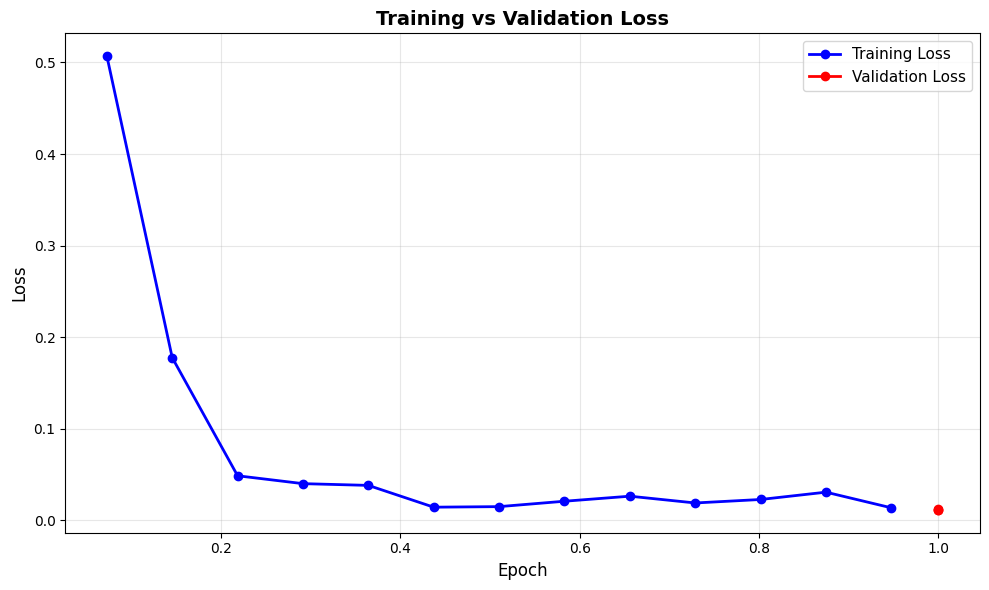

In [ ]:
# training vs validation loss
log_history = final_trainer.state.log_history

train_loss = []
val_loss = []
epochs = []

for log in log_history:
    if 'loss' in log and 'epoch' in log:
        train_loss.append(log['loss'])
        epochs.append(log['epoch'])
    if 'eval_loss' in log:
        val_loss.append(log['eval_loss'])

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_loss, 'b-o', label='Training Loss', linewidth=2)
if val_loss:
    val_epochs = [log['epoch'] for log in log_history if 'eval_loss' in log]
    plt.plot(val_epochs, val_loss, 'r-o', label='Validation Loss', linewidth=2)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('Training vs Validation Loss', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
final_trainer.save_model('/content/gdrive/MyDrive/Projek ML/best_model')
tokenizer.save_pretrained('/content/gdrive/MyDrive/Projek ML/best_model')

('/content/gdrive/MyDrive/Projek ML/best_model/tokenizer_config.json',
 '/content/gdrive/MyDrive/Projek ML/best_model/special_tokens_map.json',
 '/content/gdrive/MyDrive/Projek ML/best_model/vocab.txt',
 '/content/gdrive/MyDrive/Projek ML/best_model/added_tokens.json',
 '/content/gdrive/MyDrive/Projek ML/best_model/tokenizer.json')

In [ ]:
loaded_model = AutoModelForSequenceClassification.from_pretrained('/content/gdrive/MyDrive/Projek ML/best_model')
loaded_tokenizer = AutoTokenizer.from_pretrained('/content/gdrive/MyDrive/Projek ML/best_model')
eval_trainer = Trainer(
    model=loaded_model,
    args=training_args,
    eval_dataset=val_tok,
    processing_class=loaded_tokenizer,
    compute_metrics=compute_metrics
)

In [ ]:
eval_results = eval_trainer.evaluate()
print('Validation results:', eval_results)

test_results = eval_trainer.evaluate(test_tok)
print('Test results:', test_results)

Validation results: {'eval_loss': 0.01119497325271368, 'eval_model_preparation_time': 0.0043, 'eval_accuracy': 0.9953181527984678, 'eval_f1': 0.9953158666364228, 'eval_precision': 0.9953172453358187, 'eval_recall': 0.9953181527984678, 'eval_runtime': 33.6071, 'eval_samples_per_second': 139.822, 'eval_steps_per_second': 8.748}
Test results: {'eval_loss': 0.012280081398785114, 'eval_model_preparation_time': 0.0043, 'eval_accuracy': 0.9963822089806342, 'eval_f1': 0.9963801463396571, 'eval_precision': 0.9963830803340715, 'eval_recall': 0.9963822089806342, 'eval_runtime': 33.6595, 'eval_samples_per_second': 139.604, 'eval_steps_per_second': 8.735}



 Validation Metrics:
  Accuracy:  0.9953
  Precision: 0.9953
  Recall:    0.9953
  F1-Score:  0.9953

Classification Report (Validation):
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00      3142
     Class 1       0.99      0.99      0.99      1557

    accuracy                           1.00      4699
   macro avg       1.00      0.99      0.99      4699
weighted avg       1.00      1.00      1.00      4699



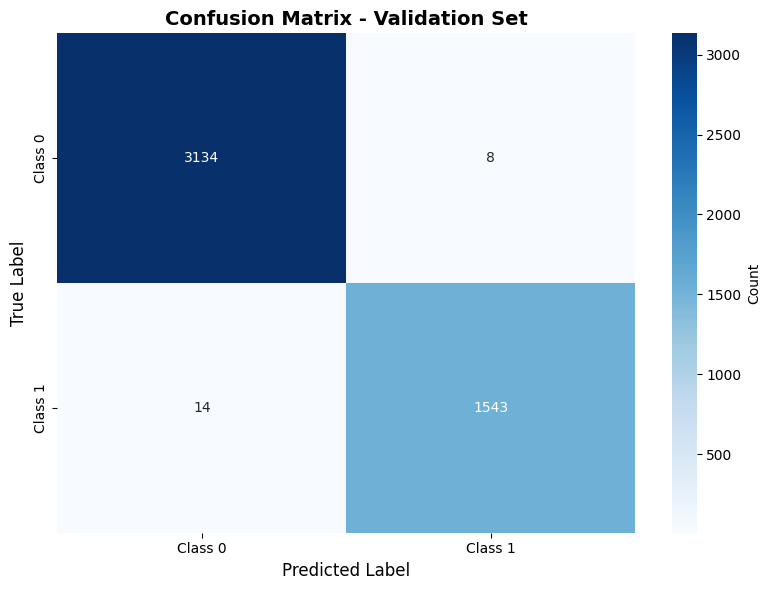

In [ ]:
# validation eval
val_predictions_bert = eval_trainer.predict(val_tok)
val_pred_labels_bert = np.argmax(val_predictions.predictions, axis=1)
val_true_labels = val_predictions.label_ids

val_accuracy_bert = accuracy_score(val_true_labels, val_pred_labels)
val_precision_bert = precision_score(val_true_labels, val_pred_labels, average='weighted')
val_recall_bert = recall_score(val_true_labels, val_pred_labels, average='weighted')
val_f1_bert = f1_score(val_true_labels, val_pred_labels, average='weighted')

print(f"\n Validation Metrics:")
print(f"  Accuracy:  {val_accuracy_bert:.4f}")
print(f"  Precision: {val_precision_bert:.4f}")
print(f"  Recall:    {val_recall_bert:.4f}")
print(f"  F1-Score:  {val_f1_bert:.4f}")

print("\nClassification Report (Validation):")
print(classification_report(val_true_labels, val_pred_labels,
                          target_names=['Class 0', 'Class 1']))

# confusion matrix validation
val_cm = confusion_matrix(val_true_labels, val_pred_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(val_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'],
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Validation Set', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()


 FINAL TEST METRICS:
  Accuracy:  0.9964
  Precision: 0.9964
  Recall:    0.9964
  F1-Score:  0.9964

 Classification Report (Test):
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00      3142
     Class 1       1.00      0.99      0.99      1557

    accuracy                           1.00      4699
   macro avg       1.00      1.00      1.00      4699
weighted avg       1.00      1.00      1.00      4699



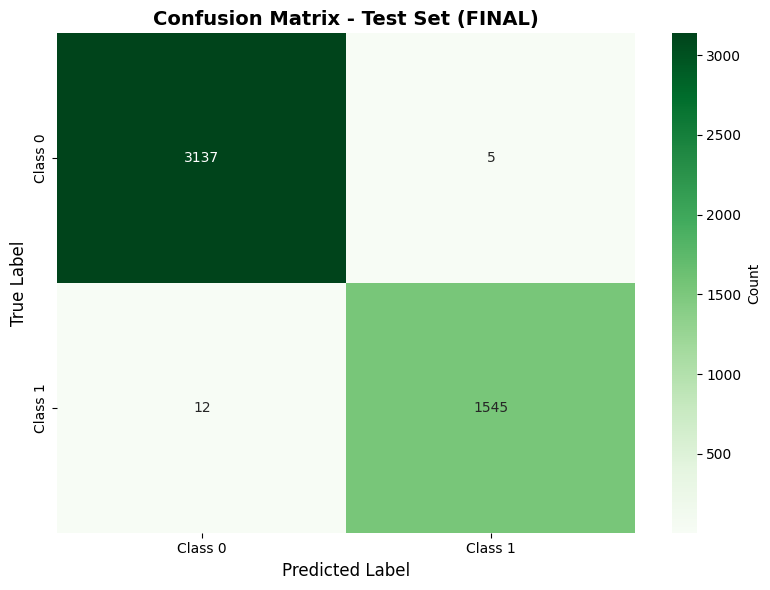

In [ ]:
# test eval
test_predictions_bert = eval_trainer.predict(test_tok)
test_pred_labels_bert = np.argmax(test_predictions.predictions, axis=1)
test_true_labels_bert = test_predictions.label_ids

test_accuracy_bert = accuracy_score(test_true_labels, test_pred_labels)
test_precision_bert = precision_score(test_true_labels, test_pred_labels, average='weighted')
test_recall_bert = recall_score(test_true_labels, test_pred_labels, average='weighted')
test_f1_bert = f1_score(test_true_labels, test_pred_labels, average='weighted')

print(f"\n FINAL TEST METRICS:")
print(f"  Accuracy:  {test_accuracy_bert:.4f}")
print(f"  Precision: {test_precision_bert:.4f}")
print(f"  Recall:    {test_recall_bert:.4f}")
print(f"  F1-Score:  {test_f1_bert:.4f}")

print("\n Classification Report (Test):")
print(classification_report(test_true_labels, test_pred_labels,
                          target_names=['Class 0', 'Class 1']))

# confusion matrix  utk test
test_cm = confusion_matrix(test_true_labels, test_pred_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'],
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Test Set (FINAL)', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

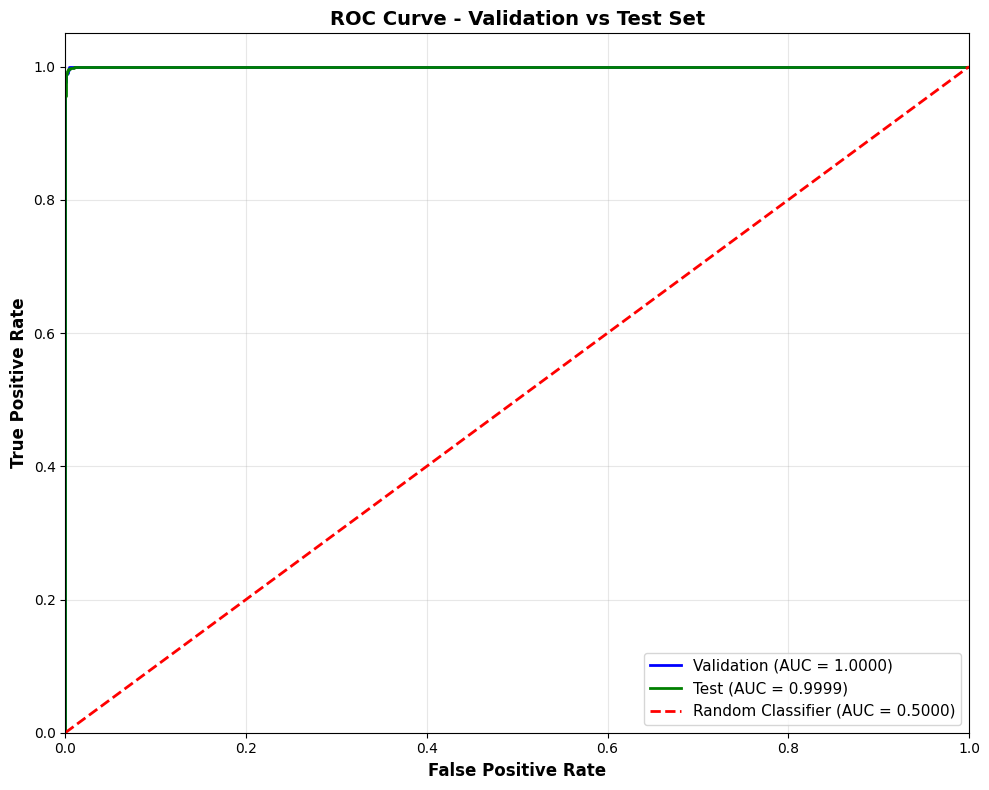


 ROC AUC Scores:
  Validation AUC: 1.0000
  Test AUC:       0.9999


In [ ]:
# roc curve
val_probs = val_predictions.predictions
test_probs = test_predictions.predictions

from scipy.special import softmax
val_probs_positive = softmax(val_probs, axis=1)[:, 1]
test_probs_positive = softmax(test_probs, axis=1)[:, 1]

val_fpr, val_tpr, val_thresholds = roc_curve(val_true_labels, val_probs_positive)
val_roc_auc_bert = auc(val_fpr, val_tpr)

test_fpr, test_tpr, test_thresholds = roc_curve(test_true_labels, test_probs_positive)
test_roc_auc_bert = auc(test_fpr, test_tpr)

plt.figure(figsize=(10, 8))
plt.plot(val_fpr, val_tpr, color='blue', lw=2,
         label=f'Validation (AUC = {val_roc_auc:.4f})')
plt.plot(test_fpr, test_tpr, color='green', lw=2,
         label=f'Test (AUC = {test_roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--',
         label='Random Classifier (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curve - Validation vs Test Set', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n ROC AUC Scores:")
print(f"  Validation AUC: {val_roc_auc_bert:.4f}")
print(f"  Test AUC:       {test_roc_auc_bert:.4f}")

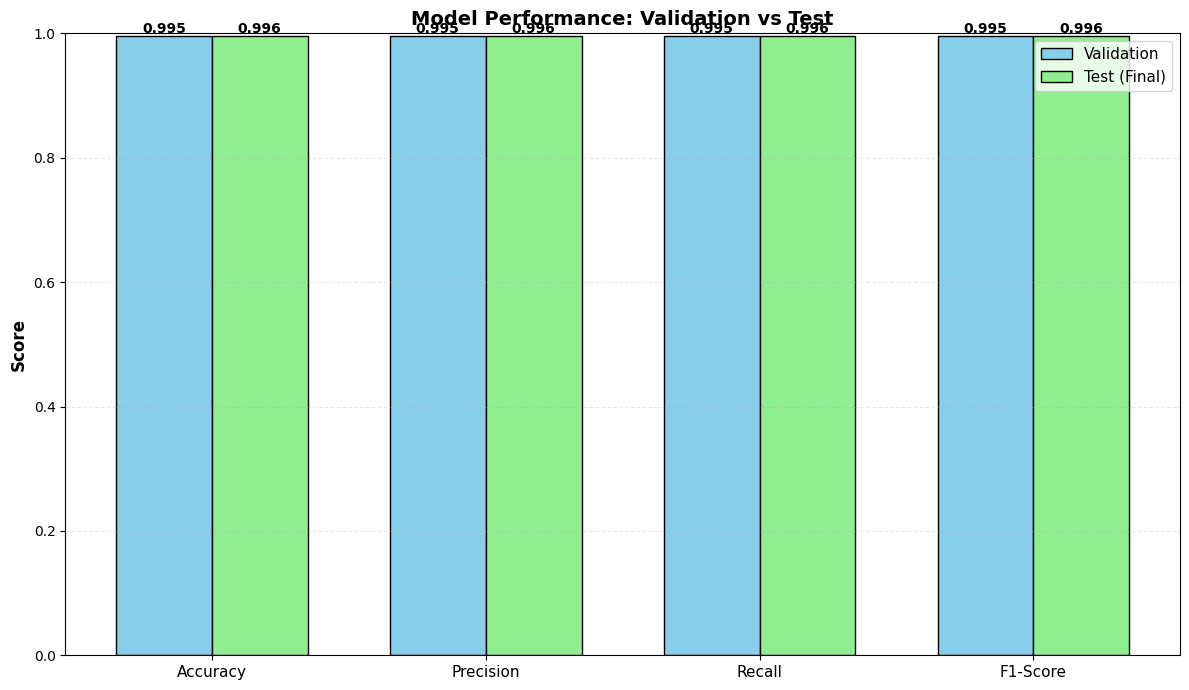

In [ ]:
# Perbandingan
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
val_scores = [val_accuracy, val_precision, val_recall, val_f1]
test_scores = [test_accuracy, test_precision, test_recall, test_f1]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 7))
bars1 = ax.bar(x - width/2, val_scores, width, label='Validation',
               color='skyblue', edgecolor='black')
bars2 = ax.bar(x + width/2, test_scores, width, label='Test (Final)',
               color='lightgreen', edgecolor='black')

ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Model Performance: Validation vs Test', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim([0, 1])
ax.grid(axis='y', alpha=0.3, linestyle='--')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
test_df_with_preds = test_df.copy()
test_df_with_preds['predicted_label'] = test_pred_labels
test_df_with_preds['correct'] = test_df_with_preds['label'] == test_df_with_preds['predicted_label']

incorrect_df = test_df_with_preds[~test_df_with_preds['correct']]

false_positives = incorrect_df[
    (incorrect_df['label'] == 0) & (incorrect_df['predicted_label'] == 1)
]

false_negatives = incorrect_df[
    (incorrect_df['label'] == 1) & (incorrect_df['predicted_label'] == 0)
]

print(f"\nTotal misclassified: {len(incorrect_df)} / {len(test_df)} ({len(incorrect_df)/len(test_df)*100:.2f}%)")
print(f"False Positives: {len(false_positives)} (predicted positive, actually negative)")
print(f"False Negatives: {len(false_negatives)} (predicted negative, actually positive)")


print("\n" + "=" * 70)
print("FALSE POSITIVES (Predicted Class 1, Actually Class 0)")
print("=" * 70)
for idx, row in false_positives.head(5).iterrows():
    print(f"\nExample {idx}:")
    print(f"  Text: {row['clean_text'][:200]}...")
    print(f"  True Label: {row['label']} | Predicted: {row['predicted_label']}")

print("FALSE NEGATIVES (Predicted Class 0, Actually Class 1)")
for idx, row in false_negatives.head(5).iterrows():
    print(f"\nExample {idx}:")
    print(f"  Text: {row['clean_text'][:200]}...")
    print(f"  True Label: {row['label']} | Predicted: {row['predicted_label']}")

incorrect_df.to_csv('misclassified_examples.csv', index=False)
print("\n\nAll misclassified examples saved to 'misclassified_examples.csv'")


Total misclassified: 17 / 4699 (0.36%)
False Positives: 5 (predicted positive, actually negative)
False Negatives: 12 (predicted negative, actually positive)

FALSE POSITIVES (Predicted Class 1, Actually Class 0)

Example 29:
  Text: tulisan seri tulisan edisi khusus perempuan kepala daerah berprestasi pilihan tempo co tulisan mendalam liputan dibaca inspirasi perempuan kepala daerah tempo co jakarta winarti meracik strategi pemba...
  True Label: 0 | Predicted: 1

Example 407:
  Text: tulisan seri tulisan edisi khusus perempuan kepala daerah berprestasi pilihan tempo co tulisan mendalam liputan dibaca inspirasi perempuan kepala daerah tempo co jakarta bupati purwakarta anne ratna m...
  True Label: 0 | Predicted: 1

Example 857:
  Text: psikolog klinis liza djaprie richard eliezer memiliki ketulusan hati maaf bertanggung liza richard bertanggung justice collaborator pembunuhan yosua simak selengkapnya gaspol eps fakta persidangan eli...
  True Label: 0 | Predicted: 1

Example 866:
  

In [ ]:
print(f"""
MODEL: IndoBERT (indobenchmark/indobert-base-p1)

VALIDATION SET:
  • Accuracy:  {val_accuracy_bert:.4f}
  • Precision: {val_precision_bert:.4f}
  • Recall:    {val_recall_bert:.4f}
  • F1-Score:  {val_f1_bert:.4f}

TEST SET (FINAL):
  • Accuracy:  {test_accuracy_bert:.4f}
  • Precision: {test_precision_bert:.4f}
  • Recall:    {test_recall_bert:.4f}
  • F1-Score:  {test_f1_bert:.4f}
  • ROC AUC:   {test_roc_auc_bert:.4f}

ERROR ANALYSIS:
  • Misclassification Rate: {len(incorrect_df)/len(test_df)*100:.2f}%
  • False Positives: {len(false_positives)}
  • False Negatives: {len(false_negatives)}
      """)


MODEL: IndoBERT (indobenchmark/indobert-base-p1)

VALIDATION SET:
  • Accuracy:  0.9953
  • Precision: 0.9953
  • Recall:    0.9953
  • F1-Score:  0.9953

TEST SET (FINAL):
  • Accuracy:  0.9964
  • Precision: 0.9964
  • Recall:    0.9964
  • F1-Score:  0.9964
  • ROC AUC:   0.9999

ERROR ANALYSIS:
  • Misclassification Rate: 0.36%
  • False Positives: 5
  • False Negatives: 12
      


In [ ]:
# Model Pembanding tf idf svm logistic regression
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

X_train = train_df['clean_text'].values
y_train = train_df['label'].values

X_val = val_df['clean_text'].values
y_val = val_df['label'].values

X_test = test_df['clean_text'].values
y_test = test_df['label'].values

In [ ]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(random_state=42, max_iter=2000))
])

In [ ]:
param_grid = {
    'tfidf__max_features': [5000, 10000, 15000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [2, 3],
    'clf__C': [0.1, 1.0, 10.0],
}

print("🚀 Starting Grid Search for Logistic Regression...")
grid_search = GridSearchCV(pipeline, param_grid, cv=3, scoring='f1_weighted', n_jobs=-1, verbose=2)
grid_search.fit(X_train, y_train)

print("\nBest parameters:")
for k, v in grid_search.best_params_.items():
    print(f"  {k}: {v}")

best_model = grid_search.best_estimator_

🚀 Starting Grid Search for Logistic Regression...
Fitting 3 folds for each of 36 candidates, totalling 108 fits

Best parameters:
  clf__C: 10.0
  tfidf__max_features: 15000
  tfidf__min_df: 2
  tfidf__ngram_range: (1, 2)


In [ ]:
# validation eval
val_pred = best_model.predict(X_val)
val_pred_proba = best_model.predict_proba(X_val)[:,1]

val_accuracy = accuracy_score(y_val, val_pred)
val_precision = precision_score(y_val, val_pred, average='weighted')
val_recall = recall_score(y_val, val_pred, average='weighted')
val_f1 = f1_score(y_val, val_pred, average='weighted')

print("\nValidation Metrics (Logistic Regression):")
print(f"Accuracy:  {val_accuracy:.4f}")
print(f"Precision: {val_precision:.4f}")
print(f"Recall:    {val_recall:.4f}")
print(f"F1-Score:  {val_f1:.4f}")
print(classification_report(y_val, val_pred, target_names=['Class 0', 'Class 1']))




Validation Metrics (Logistic Regression):
Accuracy:  0.9968
Precision: 0.9968
Recall:    0.9968
F1-Score:  0.9968
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00      3142
     Class 1       1.00      0.99      1.00      1557

    accuracy                           1.00      4699
   macro avg       1.00      1.00      1.00      4699
weighted avg       1.00      1.00      1.00      4699



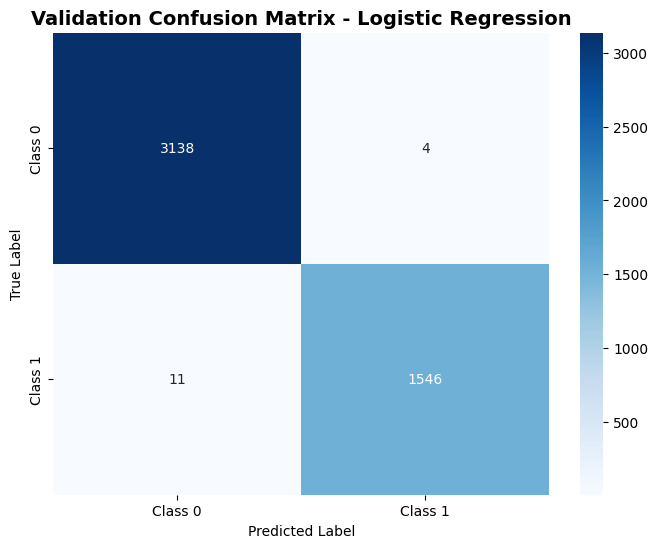

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, val_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0','Class 1'], yticklabels=['Class 0','Class 1'])
plt.title("Validation Confusion Matrix - Logistic Regression", fontsize=14, fontweight='bold')
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

In [ ]:
test_pred = best_model.predict(X_test)
test_pred_proba = best_model.predict_proba(X_test)[:,1]

test_accuracy = accuracy_score(y_test, test_pred)
test_precision = precision_score(y_test, test_pred, average='weighted')
test_recall = recall_score(y_test, test_pred, average='weighted')
test_f1 = f1_score(y_test, test_pred, average='weighted')

print("\nTest Metrics (Logistic Regression):")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(classification_report(y_test, test_pred, target_names=['Class 0', 'Class 1']))



Test Metrics (Logistic Regression):
Accuracy:  0.9977
Precision: 0.9977
Recall:    0.9977
F1-Score:  0.9977
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00      3142
     Class 1       1.00      0.99      1.00      1557

    accuracy                           1.00      4699
   macro avg       1.00      1.00      1.00      4699
weighted avg       1.00      1.00      1.00      4699



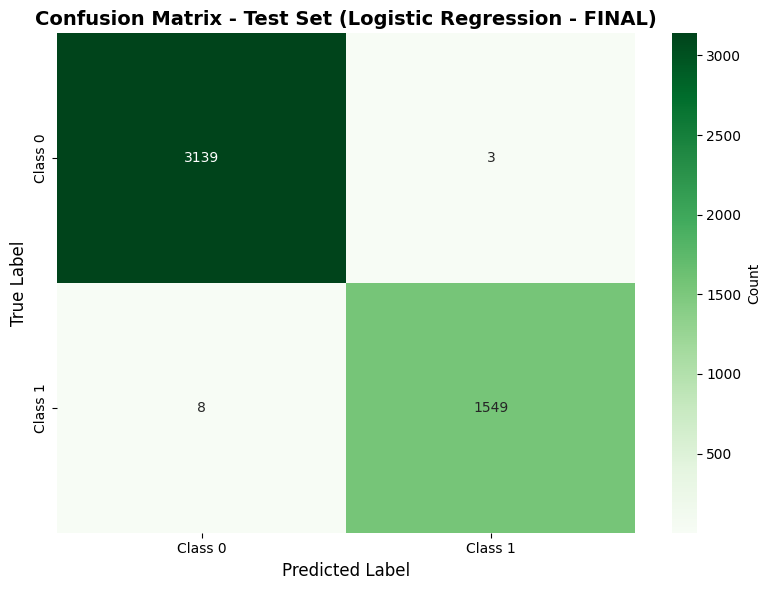

In [ ]:
test_cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'],
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Test Set (Logistic Regression - FINAL)', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

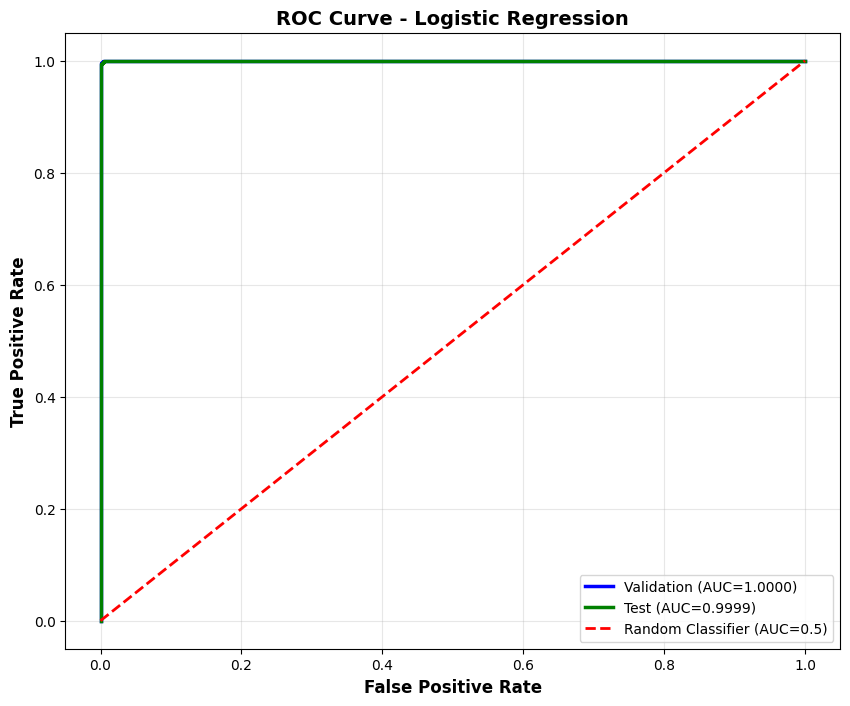

In [ ]:
val_fpr, val_tpr, _ = roc_curve(y_val, val_pred_proba)
val_roc_auc = auc(val_fpr, val_tpr)
test_fpr, test_tpr, _ = roc_curve(y_test, test_pred_proba)
test_roc_auc = auc(test_fpr, test_tpr)

plt.figure(figsize=(10,8))
plt.plot(val_fpr, val_tpr, color='blue', lw=2.5, label=f'Validation (AUC={val_roc_auc:.4f})')
plt.plot(test_fpr, test_tpr, color='green', lw=2.5, label=f'Test (AUC={test_roc_auc:.4f})')
plt.plot([0,1],[0,1], color='red', lw=2, linestyle='--', label='Random Classifier (AUC=0.5)')
plt.xlabel("False Positive Rate", fontsize=12, fontweight='bold')
plt.ylabel("True Positive Rate", fontsize=12, fontweight='bold')
plt.title("ROC Curve - Logistic Regression", fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from math import pi
bert_val_metrics = {
    "Accuracy": val_accuracy_bert,
    "Precision": val_precision_bert,
    "Recall": val_recall_bert,
    "F1-Score": val_f1_bert,
    "ROC AUC": val_roc_auc_bert
}

bert_test_metrics = {
    "Accuracy": test_accuracy_bert,
    "Precision": test_precision_bert,
    "Recall": test_recall_bert,
    "F1-Score": test_f1_bert,
    "ROC AUC": test_roc_auc_bert
}

lr_metrics_val = {
    'Accuracy': val_accuracy,
    'Precision': val_precision,
    'Recall': val_recall,
    'F1-Score': val_f1
}

lr_metrics_test = {
    'Accuracy': test_accuracy,
    'Precision': test_precision,
    'Recall': test_recall,
    'F1-Score': test_f1
}

In [ ]:
metrics_keys = ['Accuracy','Precision','Recall','F1-Score']

bert_val_metrics = {k: bert_val_metrics.get(k, np.nan) for k in metrics_keys}
bert_test_metrics = {k: bert_test_metrics.get(k, np.nan) for k in metrics_keys}
lr_metrics_val = {k: lr_metrics_val.get(k, np.nan) for k in metrics_keys}
lr_metrics_test = {k: lr_metrics_test.get(k, np.nan) for k in metrics_keys}

comparison_df = pd.DataFrame({
    "Metric": metrics_keys,
    "IndoBERT (Val)": list(bert_val_metrics.values()),
    "IndoBERT (Test)": list(bert_test_metrics.values()),
    "LR (Val)": list(lr_metrics_val.values()),
    "LR (Test)": list(lr_metrics_test.values())
})

print(comparison_df.to_string(index=False))

   Metric  IndoBERT (Val)  IndoBERT (Test)  LR (Val)  LR (Test)
 Accuracy        0.995318         0.996382  0.996808   0.997659
Precision        0.995317         0.996383  0.996809   0.997660
   Recall        0.995318         0.996382  0.996808   0.997659
 F1-Score        0.995316         0.996380  0.996806   0.997658


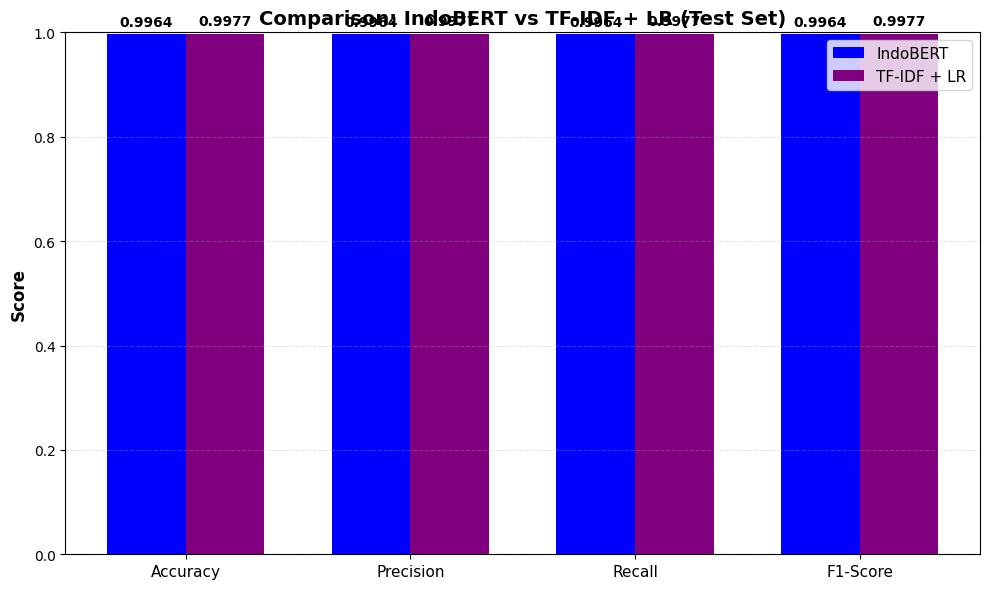

In [ ]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

bert_scores = [bert_test_metrics[m] for m in metrics]
lr_scores  = [lr_metrics_test[m] for m in metrics]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, bert_scores, width, label='IndoBERT', color='blue')
bars2 = ax.bar(x + width/2, lr_scores, width, label='TF-IDF + LR', color='purple')

ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_title('Comparison: IndoBERT vs TF-IDF + LR (Test Set)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim([0, 1])
ax.grid(axis='y', alpha=0.3, linestyle='--')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Analisis

Model yang digunakan adalah IndoBERT (indobenchmark/indobert-base-p1) untuk tugas klasifikasi biner (Class 0 dan Class 1). Evaluasi dilakukan pada validation set dan test set (final) untuk mengukur kemampuan generalisasi model.

1. Performa pada Validation Set   
Model menunjukkan performa yang sangat tinggi dan stabil pada data validasi:   

*   Accuracy: 0.9953   
*   Precision: 0.9953
*   Recall: 0.9953
*   F1-Score: 0.9953   


Analisis:   


*   Nilai precision dan recall yang seimbang menunjukkan bahwa model tidak bias terhadap salah satu kelas.
*   F1-score yang tinggi mengindikasikan keseimbangan yang baik antara false positive dan false negative.
*   Secara umum, model telah mempelajari pola data dengan sangat efektif pada tahap validasi.


2. Analisis Confusion Matrix (Validation)   
Dari total 4699 data validasi:   
•	True Negative (Class 0 → Class 0): 3134  
•	False Positive (Class 0 → Class 1): 8   
•	False Negative (Class 1 → Class 0): 14
•	True Positive (Class 1 → Class 1): 1543   
Analisis:   
•	Jumlah kesalahan klasifikasi sangat kecil (<0.5%).   
•	Kesalahan lebih banyak terjadi pada false negative, artinya beberapa data Class 1 diprediksi sebagai Class 0.  
•	Hal ini penting jika Class 1 merepresentasikan hoaks, karena false negative berarti hoaks yang tidak terdeteksi.   


3. Performa pada Test Set (Final)   
Hasil pengujian akhir    menunjukkan performa yang bahkan sedikit lebih baik:    
•	Accuracy: 0.9964    
•	Precision: 0.9964   
•	Recall: 0.9964  
•	F1-Score: 0.9964  
•	ROC AUC: 0.9999  
Analisis:   
•	Tidak terjadi penurunan performa dari validation ke test set.  
•	Ini menunjukkan tidak adanya overfitting yang signifikan.  
•	Model memiliki kemampuan generalisasi yang sangat baik terhadap data yang benar-benar baru.   


4. Analisis Confusion Matrix (Test Set)   
Dari 4699 data uji:   
•	True Negative: 3137  
•	False Positive: 5   
•	False Negative: 12  
•	True Positive: 1545    
Analisis:  
•	Total kesalahan hanya 17 data (0.36%).  
•	Jumlah false positive sangat kecil, menandakan model jarang salah menandai berita valid sebagai hoaks.  
•	False negative masih sedikit lebih dominan, konsisten dengan hasil validasi.  


5. Analisis ROC Curve   
* Validation AUC: 1.0000   
* Test AUC: 0.9999  

Analisis:
    
*	Kurva ROC hampir sempurna dan sangat jauh dari garis random classifier.   
* Nilai AUC mendekati 1 menunjukkan bahwa model sangat kuat dalam membedakan kedua kelas pada berbagai threshold.   
* Ini menandakan model tidak hanya bagus pada threshold default, tetapi juga stabil secara probabilistik.  


6. Error Analysis   
* Total misclassified: 17 / 4699 (0.36%)  
* False Positives: 5  
* False Negatives: 12  
Analisis:
* Banyak false positive berasal dari teks berita panjang, informatif, dan bernuansa opini, sehingga menyerupai ciri hoaks.
* False negative umumnya memiliki bahasa formal dan struktur menyerupai berita resmi, sehingga sulit dibedakan dari berita valid.
* Hal ini menunjukkan bahwa kesalahan model lebih disebabkan oleh ambiguitas linguistik, bukan kelemahan arsitektur.


Perbandingan dengan Model Baseline (TF IDF Logistic Regression)

Sebagai pembanding (baseline), digunakan Logistic Regression (LR) untuk tugas klasifikasi hoaks yang sama. Perbandingan ini bertujuan untuk menilai sejauh mana model berbasis pre-trained language model (IndoBERT) memberikan peningkatan performa dibandingkan metode klasik.

1. Perbandingan Metrik Evaluasi  

Berdasarkan hasil evaluasi pada validation set dan test set, diperoleh ringkasan kinerja sebagai berikut:   
* IndoBERT (Test Set):   
Accuracy: 0.9964  
Precision: 0.9964  
Recall: 0.9964  
F1-Score: 0.9964  
* Logistic Regression (Test Set):  
Accuracy: 0.9977  
Precision: 0.9977  
Recall: 0.9977  
F1-Score: 0.9977  

Secara numerik, Logistic Regression menunjukkan nilai metrik yang sedikit lebih tinggi. Namun, perbedaan ini sangat kecil (≈0.1%) dan tidak signifikan secara praktis.



2. Analisis Confusion Matrix Logistic Regression   
Pada test data, confusion matrix Logistic Regression menunjukkan:  
*	True Negative (Class 0 = Class 0): 3139  
*	False Positive (Class 0 = Class 1): 3  
*	False Negative (Class 1 = Class 0): 8  
*	True Positive (Class 1 = Class 1): 1549   
Total kesalahan hanya 11 dari 4699 data (0.23%), menandakan bahwa Logistic Regression bekerja sangat baik pada dataset ini.  
Namun demikian, pola kesalahan masih menunjukkan bahwa false negative lebih dominan, yang berisiko jika Class 1 merepresentasikan hoaks.  


3. Analisis ROC Curve   

*	Logistic Regression (Test AUC): ≈ 1.000  
*	IndoBERT (Test AUC): 0.9999  

Kedua model memiliki kurva ROC yang hampir sempurna dan jauh di atas garis random classifier. Hal ini menunjukkan bahwa baik IndoBERT maupun Logistic Regression memiliki kemampuan diskriminatif yang sangat tinggi dalam membedakan berita hoaks dan non-hoaks.


Meskipun Logistic Regression menghasilkan metrik evaluasi yang sedikit lebih tinggi, beberapa poin penting perlu diperhatikan:  
1.	IndoBERT unggul secara representasi linguistik, karena mampu menangkap konteks semantik, hubungan antar-kata, dan makna implisit dalam teks bahasa Indonesia.  
2.	Logistic Regression sangat bergantung pada fitur statistik (misalnya TF-IDF), sehingga performanya sangat dipengaruhi oleh karakteristik dataset.  
3.	IndoBERT cenderung lebih unggul untuk generalisasi lintas domain, terutama pada teks dengan struktur kompleks, gaya bahasa tidak baku, atau konteks implisit.  
4.	Selisih performa yang sangat kecil menunjukkan bahwa dataset memiliki pola yang cukup terstruktur, sehingga model klasik pun dapat bekerja sangat optimal.  


Berdasarkan grafik Training dan Validation Loss, dapat dilihat bahwa training loss terus menunjukkan penurunan yang stabil seiring dengan bertambahnya epoch. Dalam fase awal pelatihan, nilai loss cukup tinggi dan selanjutnya menurun drastis hingga mencapai nilai yang konsisten. Pola ini menunjukkan bahwa proses optimisasi berlangsung baik dan model dapat mempelajari pola pada data pelatihan dengan efektif.

Nilai validation loss hanya dicatat pada satu titik, yaitu pada akhir proses pelatihan. Hal ini disebabkan oleh strategi evaluasi yang dilakukan satu kali di akhir training untuk mengurangi beban komputasi, mengingat evaluasi pada data validasi memerlukan biaya komputasi yang cukup tinggi, terutama pada model berbasis transformer. Pendekatan ini difokuskan untuk memperoleh performa akhir model tanpa menambah overhead komputasi selama proses pelatihan.

Walaupun begitu, nilai akhir validation loss yang cukup rendah dan mendekati training loss menunjukkan bahwa model menunjukkan kemampuan generalisasi yang cukup baik pada data validasi. Namun, karena validation loss tidak dianalisis di setiap epoch, pemeriksaan terhadap dinamika pembelajaran model, seperti tanda-tanda overfitting atau penentuan epoch terbaik, tidak dapat dilakukan secara menyeluruh.

Kesimpulan

Kesimpulan Analisis Model  
1.	Model IndoBERT menunjukkan kinerja sangat tinggi dan konsisten pada validation dan test set.  
2.	Tidak ditemukan indikasi overfitting yang signifikan.  
3.	ROC AUC yang hampir sempurna menegaskan kemampuan diskriminatif model.  
4.	Kesalahan klasifikasi sangat kecil dan sebagian besar terjadi pada kasus teks yang ambigu secara semantik.  
5.	Model layak digunakan untuk sistem deteksi hoaks otomatis pada teks berita dan media sosial berbahasa Indonesia.  
6. Logistic Regression cocok sebagai baseline yang kuat dan efisien secara komputasi.
7. IndoBERT menawarkan keunggulan konseptual dan fleksibilitas jangka panjang, terutama untuk pengembangan sistem deteksi hoaks skala besar dan lintas domain.  
8. Dengan mempertimbangkan aspek performa, robustness, dan kemampuan pemahaman bahasa, IndoBERT tetap menjadi model yang lebih direkomendasikan untuk implementasi sistem deteksi hoaks berbasis NLP modern.  


